# DSCI 552 — Homework 5

**Name:** Gina Mao
**GitHub Username:** ruoxuanm116
**USC ID:** 8885483334

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")
RANDOM_STATE = 552
np.random.seed(RANDOM_STATE)

# 1. Decision Trees as Interpretable Models
## 1(a) Download the Acute Inflammations data

The file `diagnosis.data` is UTF-16 encoded, tab-separated, and uses a decimal comma for temperature.

| Column | Meaning |
|---|---|
| a1 | Temperature of patient (35–42 °C) |
| a2 | Occurrence of nausea |
| a3 | Lumbar pain |
| a4 | Urine pushing (continuous need for urination) |
| a5 | Micturition pains |
| a6 | Burning of urethra, itch, swelling of urethra outlet |
| d1 | Decision: Inflammation of urinary bladder |
| d2 | Decision: Nephritis of renal pelvis origin |

In [ ]:
cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
        "micturition_pains", "burning_urethra", "inflammation", "nephritis"]
acute = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, names=cols,
                    encoding="utf-16", decimal=",")
for c in cols[1:]:
    acute[c] = acute[c].str.strip().map({"yes": 1, "no": 0})
print(acute.shape)
acute.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


## 1(b) Build a decision tree on the whole data set and plot it

This is a **multi-label** problem (two binary labels). I use the **label powerset** method: each combination of
(inflammation, nephritis) becomes one class, giving a multiclass problem.

**Is label powerset more relevant here? Yes.** There are only 2 labels, so at most 4 combined classes, and all
of them occur with enough samples (see counts below). The powerset keeps the dependence between the two
diagnoses (e.g. the same symptoms can point to both diseases at once) in a *single* tree, which gives one set of
rules that is easier to read than two separate trees (binary relevance).

Inflammation only    40
Nephritis only       31
None                 30
Both                 19
Name: count, dtype: int64
Training accuracy: 1.0
Depth: 4  Leaves: 6


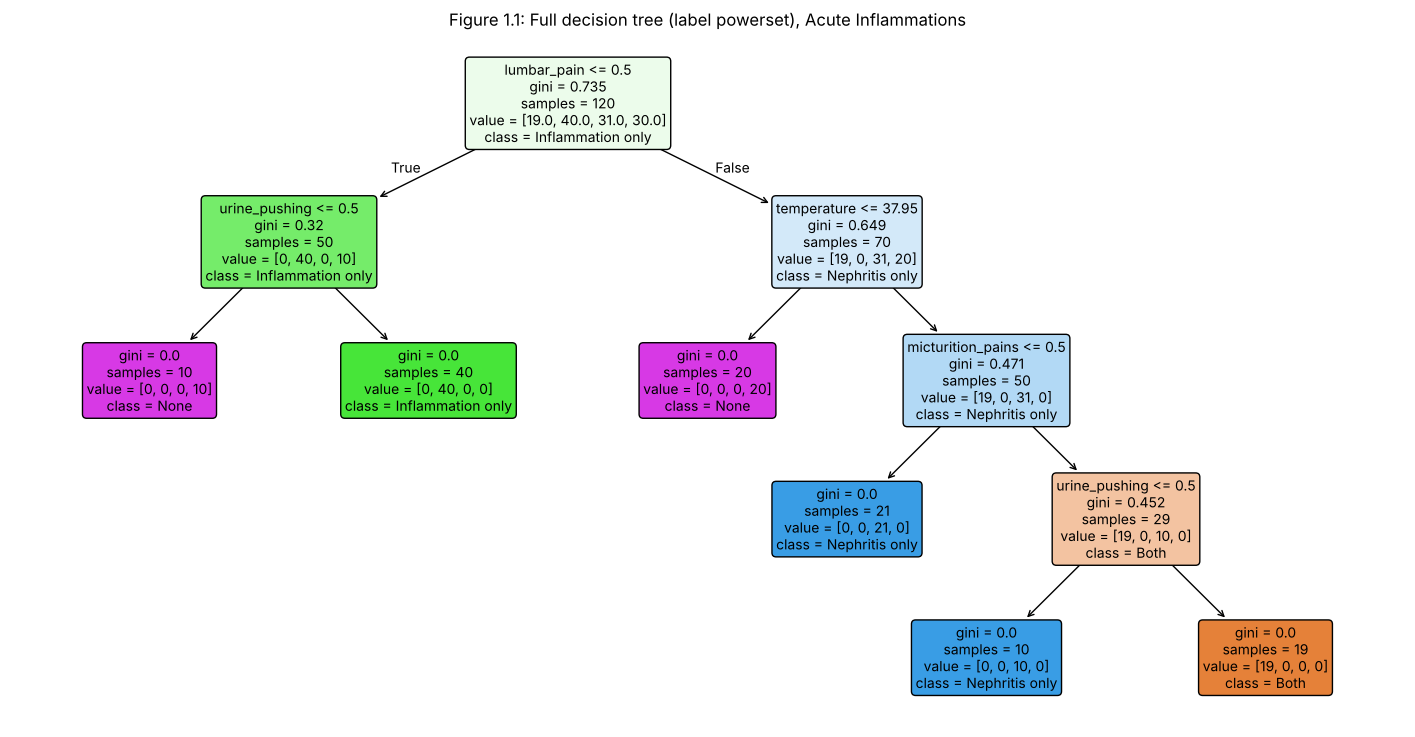

In [ ]:
X1 = acute[cols[:6]]
label_map = {(0, 0): "None", (1, 0): "Inflammation only",
             (0, 1): "Nephritis only", (1, 1): "Both"}
y1 = acute.apply(lambda r: label_map[(r["inflammation"], r["nephritis"])], axis=1)
print(y1.value_counts())

tree_full = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_full.fit(X1, y1)
print("Training accuracy:", tree_full.score(X1, y1))
print("Depth:", tree_full.get_depth(), " Leaves:", tree_full.get_n_leaves())

fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(tree_full, feature_names=X1.columns, class_names=tree_full.classes_,
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title("Figure 1.1: Full decision tree (label powerset), Acute Inflammations")
plt.show()

## 1(c) Convert the decision rules into a set of IF-THEN rules

The function below is adapted from the KDnuggets article *Simplifying Decision Tree Interpretability with Python & Scikit-learn*.
Each root-to-leaf path becomes one rule. All symptom features are binary (0/1), so `feature <= 0.5` means **no** and
`feature > 0.5` means **yes**.

In [ ]:
def get_rules(tree, feature_names, class_names):
    t = tree.tree_
    feat_name = [feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined" for i in t.feature]
    paths = []

    def recurse(node, path):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = feat_name[node], t.threshold[node]
            recurse(t.children_left[node], path + [(name, "<=", thr)])
            recurse(t.children_right[node], path + [(name, ">", thr)])
        else:
            paths.append((path, t.value[node][0], int(t.n_node_samples[node])))

    recurse(0, [])
    paths.sort(key=lambda p: -p[2])

    def cond_text(name, op, thr):
        if name == "temperature":
            return f"temperature {op} {thr:.2f}"
        return f"{name} = {'no' if op == '<=' else 'yes'}"

    rules = []
    for path, value, n in paths:
        cls = class_names[int(np.argmax(value))]
        conds = " AND ".join(cond_text(*c) for c in path) if path else "TRUE"
        rules.append(f"IF {conds} THEN diagnosis = {cls}   (samples = {n})")
    return rules

for i, r in enumerate(get_rules(tree_full, list(X1.columns), tree_full.classes_), 1):
    print(f"Rule {i}: {r}")

Rule 1: IF lumbar_pain = no AND urine_pushing = yes THEN diagnosis = Inflammation only   (samples = 40)
Rule 2: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN diagnosis = Nephritis only   (samples = 21)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN diagnosis = None   (samples = 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = Both   (samples = 19)
Rule 5: IF lumbar_pain = no AND urine_pushing = no THEN diagnosis = None   (samples = 10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = Nephritis only   (samples = 10)


## 1(d) Cost-complexity pruning for a minimal, interpretable tree

I compute the cost-complexity pruning path ($\alpha$ values), evaluate each pruned tree with 5-fold stratified
cross-validation, and pick the **largest** $\alpha$ whose CV accuracy is still equal to the best CV accuracy.
The largest such $\alpha$ gives the smallest tree that does not lose accuracy, i.e. the most interpretable one.

,ccp_alpha,cv_accuracy,n_leaves
0,0.000000,0.991667,6
1,0.098167,0.858333,4
2,0.133333,0.766667,3
3,0.182000,0.675000,2


Chosen ccp_alpha = 0.00000 (CV accuracy = 0.9917)


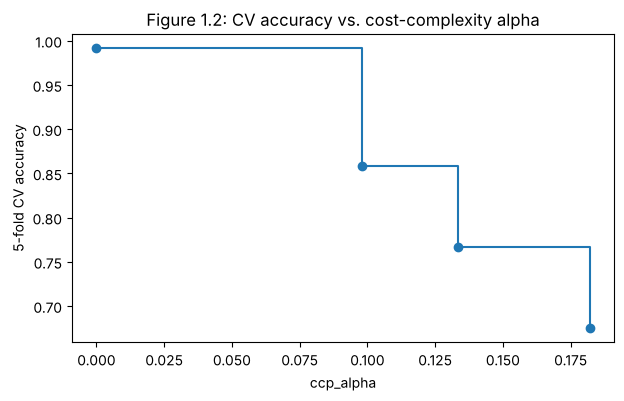

In [ ]:
path = tree_full.cost_complexity_pruning_path(X1, y1)
ccp_alphas = path.ccp_alphas[:-1]   # last alpha gives a single-node tree
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

res = []
for a in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    acc = cross_val_score(clf, X1, y1, cv=cv5).mean()
    leaves = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a).fit(X1, y1).get_n_leaves()
    res.append((a, acc, leaves))
prune_df = pd.DataFrame(res, columns=["ccp_alpha", "cv_accuracy", "n_leaves"])
display(prune_df)

best_acc = prune_df["cv_accuracy"].max()
best_alpha = prune_df.loc[np.isclose(prune_df["cv_accuracy"], best_acc), "ccp_alpha"].max()
print(f"Chosen ccp_alpha = {best_alpha:.5f} (CV accuracy = {best_acc:.4f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(prune_df["ccp_alpha"], prune_df["cv_accuracy"], marker="o", drawstyle="steps-post")
ax.set_xlabel("ccp_alpha"); ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Figure 1.2: CV accuracy vs. cost-complexity alpha")
plt.show()

Pruned tree  -> depth: 4  leaves: 6  training accuracy: 1.0


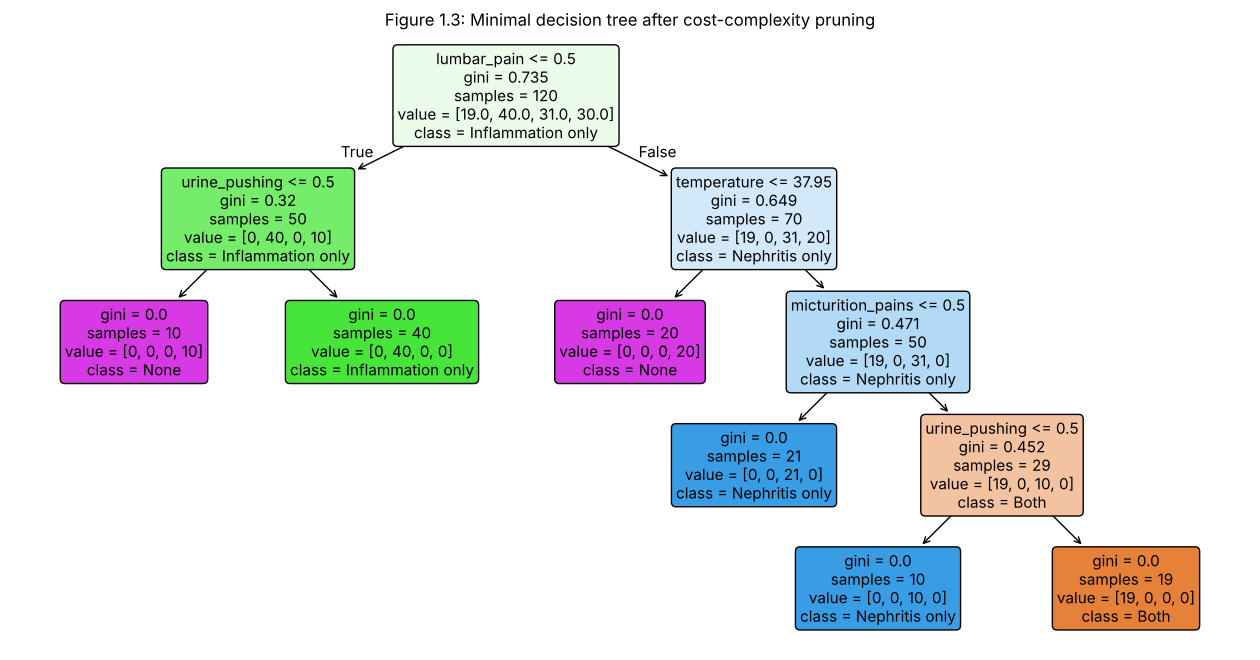

IF-THEN rules of the pruned tree:
Rule 1: IF lumbar_pain = no AND urine_pushing = yes THEN diagnosis = Inflammation only   (samples = 40)
Rule 2: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN diagnosis = Nephritis only   (samples = 21)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN diagnosis = None   (samples = 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = Both   (samples = 19)
Rule 5: IF lumbar_pain = no AND urine_pushing = no THEN diagnosis = None   (samples = 10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = Nephritis only   (samples = 10)


In [ ]:
tree_pruned = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=best_alpha).fit(X1, y1)
print("Pruned tree  -> depth:", tree_pruned.get_depth(), " leaves:", tree_pruned.get_n_leaves(),
      " training accuracy:", tree_pruned.score(X1, y1))

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree_pruned, feature_names=X1.columns, class_names=tree_pruned.classes_,
          filled=True, rounded=True, fontsize=11, ax=ax)
ax.set_title("Figure 1.3: Minimal decision tree after cost-complexity pruning")
plt.show()

print("IF-THEN rules of the pruned tree:")
for i, r in enumerate(get_rules(tree_pruned, list(X1.columns), tree_pruned.classes_), 1):
    print(f"Rule {i}: {r}")

**Conclusion for 1(d):** The pruning path has only 4 candidate subtrees (6, 4, 3 and 2 leaves). The 6-leaf tree has the
best CV accuracy (about 99%). Pruning to 4 leaves drops CV accuracy to about 86%, and smaller trees are worse.
So cost-complexity pruning selects $\alpha = 0$: **the tree from 1(b) is already the minimal tree** with high accuracy.
With 4 classes, any tree needs at least 4 leaves, and 6 leaves is close to that lower bound.

The final rule set is very interpretable: only 4 of the 6 features are used (`nausea` and `burning_urethra` are never needed),
and each rule has at most 4 conditions. In short:
- no lumbar pain + urine pushing → inflammation of the bladder only;
- lumbar pain + temperature ≤ 37.95 °C → neither disease;
- lumbar pain + fever (> 37.95 °C) → nephritis, and also bladder inflammation if micturition pains **and** urine pushing are present.

For comparison, the 4-leaf tree (next $\alpha$ on the path) is shown below. It is simpler but misclassifies many more patients,
so it is not chosen.

In [ ]:
alpha_4 = prune_df.loc[prune_df["n_leaves"] == 4, "ccp_alpha"].iloc[0]
tree_4 = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=alpha_4).fit(X1, y1)
print(f"4-leaf tree: ccp_alpha = {alpha_4:.4f}, training accuracy = {tree_4.score(X1, y1):.3f}")
for i, r in enumerate(get_rules(tree_4, list(X1.columns), tree_4.classes_), 1):
    print(f"Rule {i}: {r}")

4-leaf tree: ccp_alpha = 0.0982, training accuracy = 0.842
Rule 1: IF lumbar_pain = yes AND temperature > 37.95 THEN diagnosis = Nephritis only   (samples = 50)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN diagnosis = Inflammation only   (samples = 40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN diagnosis = None   (samples = 20)
Rule 4: IF lumbar_pain = no AND urine_pushing = no THEN diagnosis = None   (samples = 10)


# 2. The LASSO and Boosting for Regression
## 2(a) Download the Communities and Crime data

Column names are parsed from the `@attribute` lines in `communities.names`. Missing values are coded as `?`.
The first 1495 rows are the training set and the rest are the test set.

In [ ]:
with open("../data/communities.names", "r") as f:
    names = re.findall(r"^@attribute\s+(\S+)", f.read(), flags=re.M)
crime = pd.read_csv("../data/communities.data", header=None, names=names, na_values="?")
print(crime.shape)
crime.head()

(1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


## 2(b) Missing values and non-predictive features

The description says `state`, `county`, `community`, `communityname` and `fold` are non-predictive, so they are dropped.
This leaves **122 predictive features** and the target `ViolentCrimesPerPop`.

23 features have missing values. 22 of them are police (LEMAS) statistics that are missing for 1675 of the 1994
communities (about 84%), and `OtherPerCap` is missing once. I keep these features, because the assignment asks for
imputation rather than removal.

For imputation I use **median imputation**. The median is robust to the skewed distributions in this data. The imputer is fitted on the **training set only** and then applied
to both sets, so no test information leaks into training.

In [ ]:
non_predictive = ["state", "county", "community", "communityname", "fold"]
crime = crime.drop(columns=non_predictive)
target = "ViolentCrimesPerPop"

train = crime.iloc[:1495].reset_index(drop=True)
test = crime.iloc[1495:].reset_index(drop=True)
X_train_raw, y_train = train.drop(columns=target), train[target]
X_test_raw, y_test = test.drop(columns=target), test[target]
print("Train:", X_train_raw.shape, " Test:", X_test_raw.shape)

miss = crime.isna().sum()
print("Features with missing values:", (miss > 0).sum())
print(miss[miss > 0].sort_values(ascending=False))

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)
print("Missing values left (train, test):", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Train: (1495, 122)  Test: (499, 122)
Features with missing values: 23
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasTotalReq           1675
LemasSwFTFieldPerPop    1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
OfficAssgnDrugUnits     1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
PolicOperBudg           1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
LemasGangUnitDeploy     1675
LemasPctPolicOnPatr     1675
PolicBudgPerPop         1675
OtherPerCap                1
dtype: int64
Missing values left (train, test): 0 0


## 2(c) Correlation matrix of the features

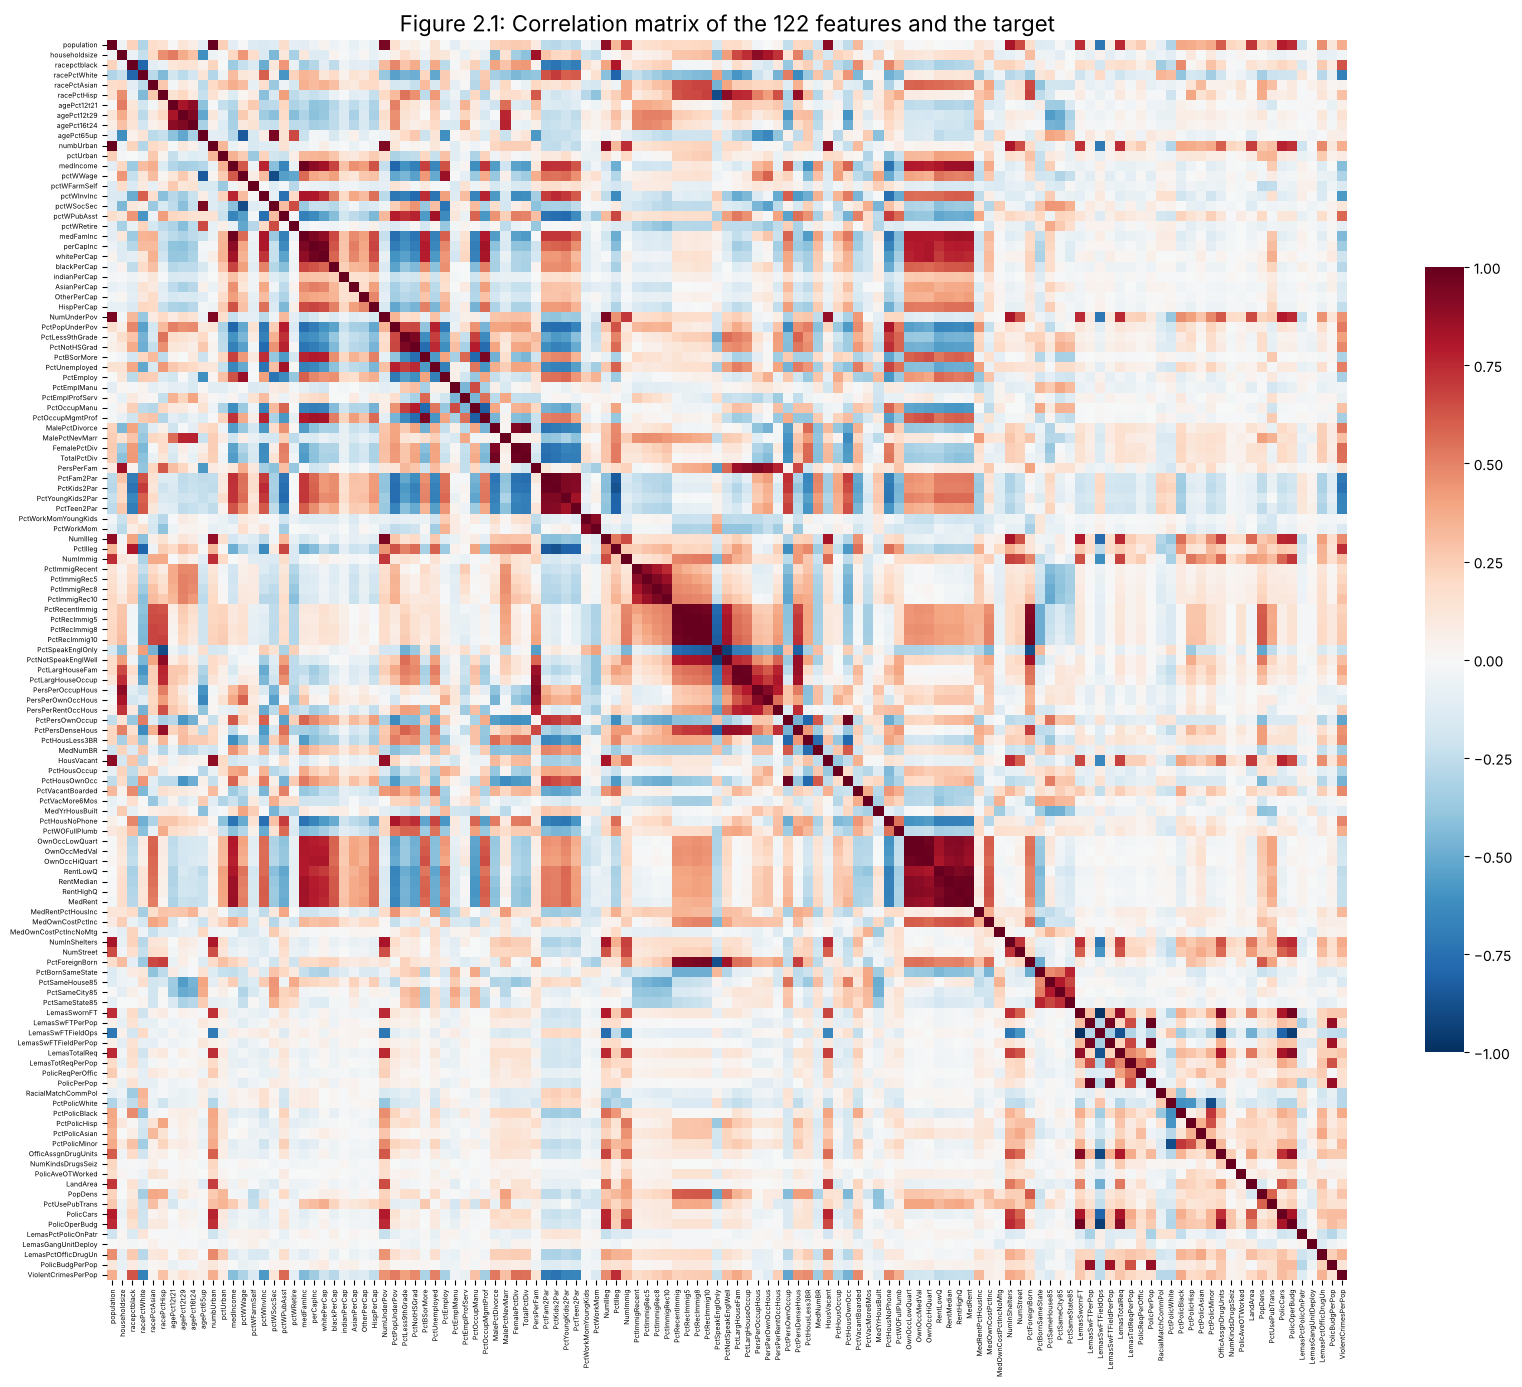

Top 10 features most correlated with the target:
PctKids2Par         0.738424
PctIlleg            0.737957
PctFam2Par          0.706667
racePctWhite        0.684770
PctYoungKids2Par    0.666059
PctTeen2Par         0.661582
racepctblack        0.631264
pctWInvInc          0.576324
pctWPubAsst         0.574665
FemalePctDiv        0.556032
Name: ViolentCrimesPerPop, dtype: float64


In [ ]:
data_full = pd.concat([pd.concat([X_train, y_train], axis=1),
                       pd.concat([X_test, y_test], axis=1)], ignore_index=True)
corr = data_full.corr()

fig, ax = plt.subplots(figsize=(20, 17))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6}, ax=ax)
ax.tick_params(labelsize=5)
ax.set_title("Figure 2.1: Correlation matrix of the 122 features and the target", fontsize=16)
plt.show()

print("Top 10 features most correlated with the target:")
print(corr[target].drop(target).abs().sort_values(ascending=False).head(10))

## 2(d) Coefficient of Variation $CV = s/m$ for each feature

In [ ]:
X_all = data_full.drop(columns=target)
cv_df = pd.DataFrame({"mean": X_all.mean(), "std": X_all.std(ddof=1)})
cv_df["CV"] = cv_df["std"] / cv_df["mean"]
cv_df = cv_df.sort_values("CV", ascending=False)
pd.set_option("display.max_rows", 130)
cv_df

,mean,std,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
NumUnderPov,0.055507,0.127941,2.304970
population,0.057593,0.126906,2.203503
LemasSwornFT,0.027944,0.058143,2.080712
numbUrban,0.064072,0.128256,2.001744


## 2(e) Scatter plots and box plots for the $\lfloor\sqrt{128}\rfloor = 11$ features with highest CV

11 features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


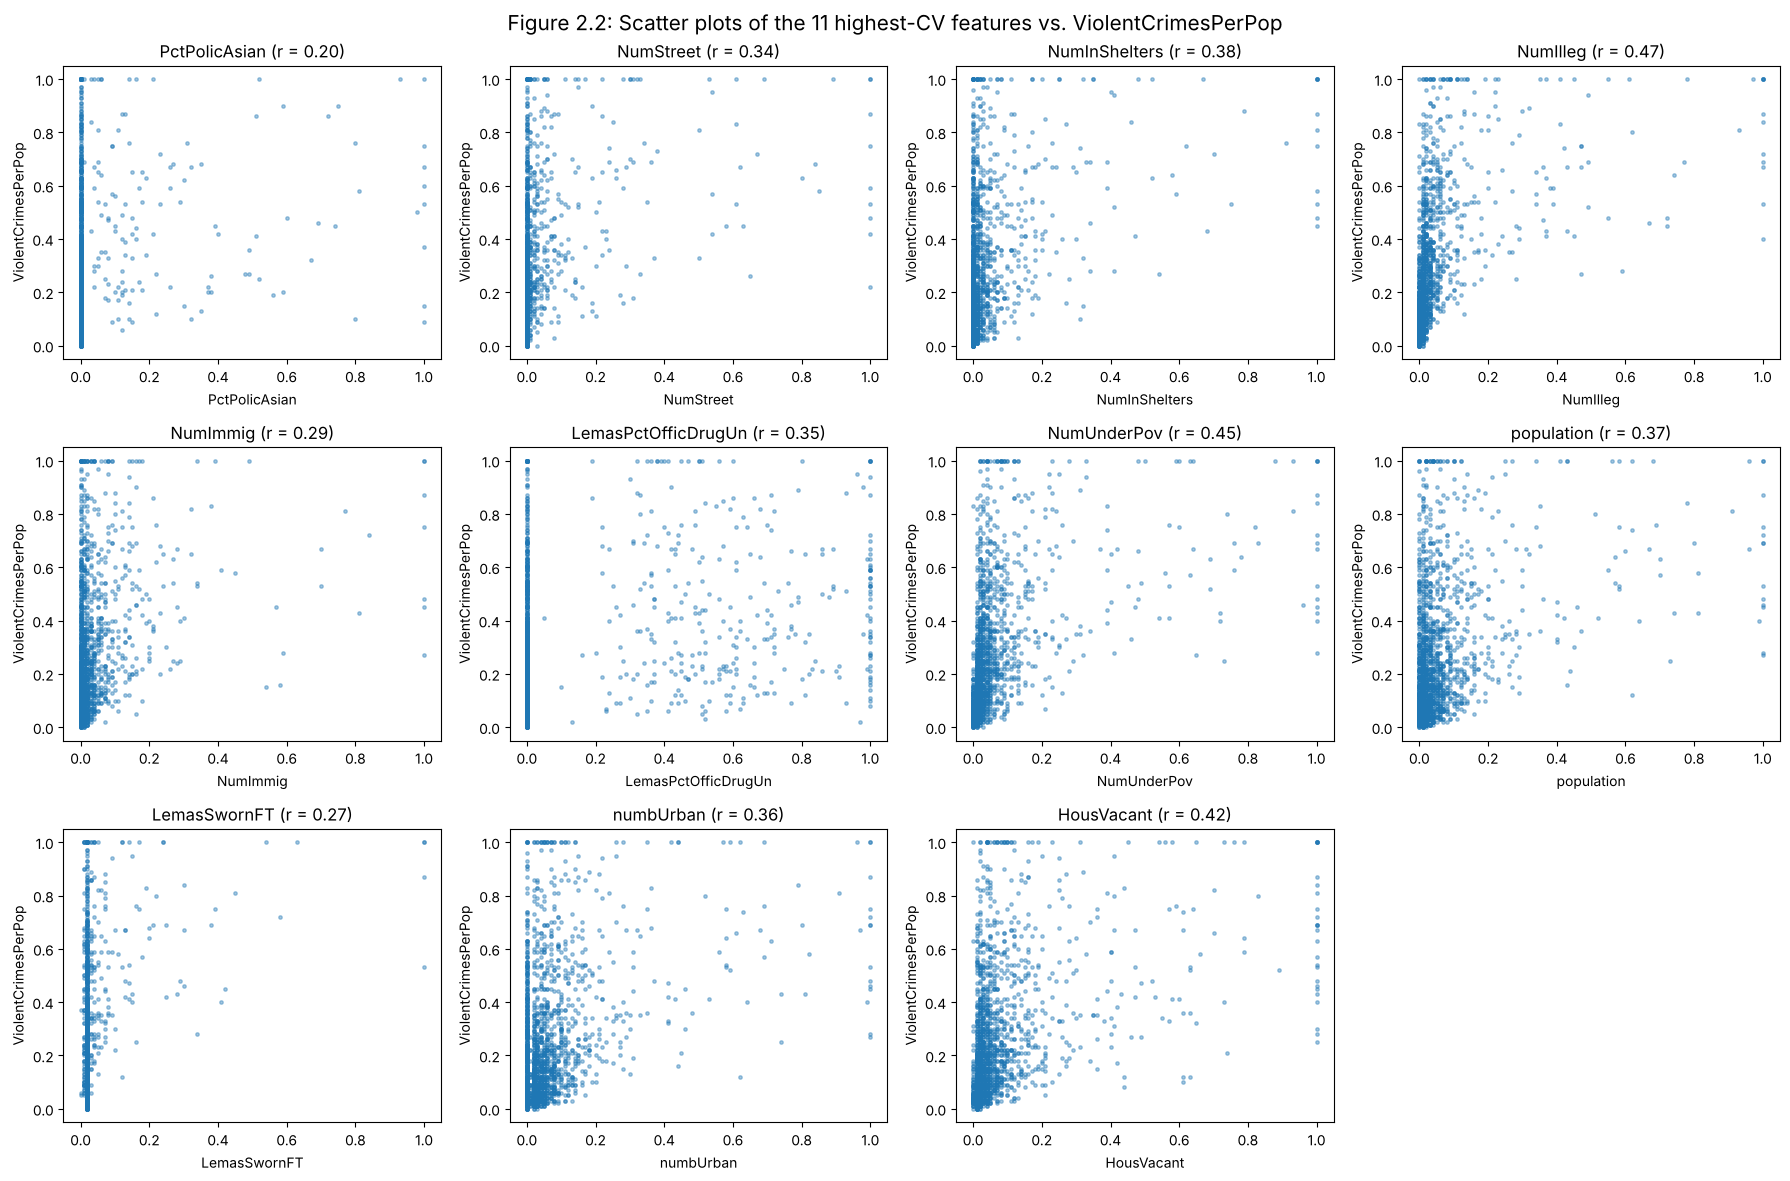

In [ ]:
k = int(np.floor(np.sqrt(128)))
top_cv = cv_df.index[:k].tolist()
print(k, "features:", top_cv)

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, f in zip(axes.flat, top_cv):
    ax.scatter(data_full[f], data_full[target], s=6, alpha=0.4)
    ax.set_xlabel(f); ax.set_ylabel(target)
    ax.set_title(f"{f} (r = {corr.loc[f, target]:.2f})")
axes.flat[-1].axis("off")
fig.suptitle("Figure 2.2: Scatter plots of the 11 highest-CV features vs. ViolentCrimesPerPop", fontsize=15)
plt.tight_layout(); plt.show()

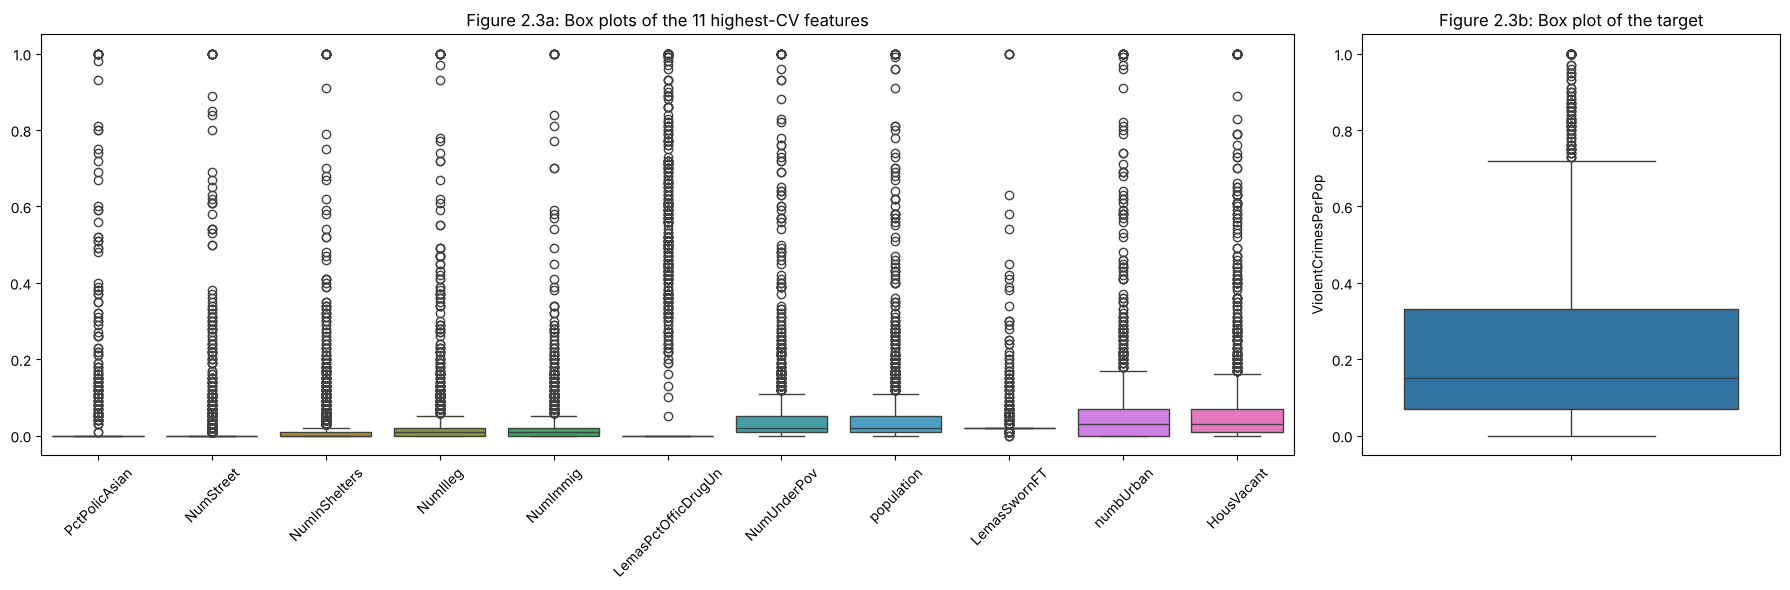

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [3, 1]})
sns.boxplot(data=data_full[top_cv], ax=axes[0])
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Figure 2.3a: Box plots of the 11 highest-CV features")
sns.boxplot(y=data_full[target], ax=axes[1])
axes[1].set_title("Figure 2.3b: Box plot of the target")
plt.tight_layout(); plt.show()

**Can we conclude significance from the scatter plots alone? No.**

A few of the high-CV features (for example `NumIlleg`, `NumUnderPov`, `NumInShelters`, `NumImmig`, `PctNotSpeakEnglWell`)
show a weak upward trend, but most points are piled up near 0 (heavily right-skewed) and the spread of the target is
large at every value. The box plots confirm this: most of these features have tiny medians and many outliers. A high CV
only means a feature varies a lot relative to its mean; it does not say the feature is related to the target. Scatter
plots show only one-variable (marginal) relationships and ignore correlations among the features, so they cannot
establish statistical significance. That needs a fitted model (p-values, or variable selection such as the LASSO below).

## 2(f) Linear model with least squares

In [ ]:
ols = LinearRegression().fit(X_train, y_train)
mse_ols = mean_squared_error(y_test, ols.predict(X_test))
print(f"OLS test MSE = {mse_ols:.5f}")
results = {"Least squares": mse_ols}

OLS test MSE = 0.01797


## 2(g) Ridge regression with $\lambda$ chosen by cross-validation

In [ ]:
kf10 = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-4, 3, 200)
ridge = RidgeCV(alphas=alphas, cv=kf10, scoring="neg_mean_squared_error").fit(X_train, y_train)
mse_ridge = mean_squared_error(y_test, ridge.predict(X_test))
print(f"Best lambda = {ridge.alpha_:.5f}")
print(f"Ridge test MSE = {mse_ridge:.5f}")
results["Ridge"] = mse_ridge

Best lambda = 2.12145
Ridge test MSE = 0.01753


## 2(h) LASSO with $\lambda$ chosen by cross-validation

### (i) On the given (already normalized) features

In [ ]:
lasso = LassoCV(cv=kf10, alphas=200, max_iter=100000, random_state=RANDOM_STATE).fit(X_train, y_train)
mse_lasso = mean_squared_error(y_test, lasso.predict(X_test))
sel = X_train.columns[lasso.coef_ != 0]
print(f"Best lambda = {lasso.alpha_:.6f}")
print(f"LASSO test MSE = {mse_lasso:.5f}")
print(f"{len(sel)} variables selected:")
display(pd.Series(lasso.coef_[lasso.coef_ != 0], index=sel, name="coef").sort_values(key=abs, ascending=False))
results["LASSO"] = mse_lasso

Best lambda = 0.000082
LASSO test MSE = 0.01769
79 variables selected:


agePct12t29             -0.320757
racepctblack             0.269781
PctPersDenseHous         0.238395
PctKids2Par             -0.201401
MedRent                  0.183048
PctEmploy                0.175875
MalePctNevMarr           0.172625
RentLowQ                -0.171477
NumStreet                0.163898
PctPopUnderPov          -0.160229
MalePctDivorce           0.146960
PctWorkMom              -0.141849
HousVacant               0.131116
pctWInvInc              -0.127397
FemalePctDiv            -0.119809
PersPerOccupHous         0.118342
NumImmig                -0.117736
PctLargHouseOccup       -0.111487
pctWRetire              -0.111422
NumIlleg                -0.109147
PolicReqPerOffic         0.104548
pctWWage                -0.100859
PctNotSpeakEnglWell     -0.095725
PctIlleg                 0.093138
MedRentPctHousInc        0.091310
agePct12t21              0.083828
whitePerCap             -0.082999
LemasSwFTFieldPerPop     0.081642
MedOwnCostPctIncNoMtg   -0.081194
NumInShelters 

### (ii) On standardized features (zero mean, unit variance; scaler fitted on the training set)

In [ ]:
scaler = StandardScaler().fit(X_train)
X_train_std = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

lasso_std = LassoCV(cv=kf10, alphas=200, max_iter=100000, random_state=RANDOM_STATE).fit(X_train_std, y_train)
mse_lasso_std = mean_squared_error(y_test, lasso_std.predict(X_test_std))
sel_std = X_train.columns[lasso_std.coef_ != 0]
print(f"Best lambda = {lasso_std.alpha_:.6f}")
print(f"LASSO (standardized) test MSE = {mse_lasso_std:.5f}")
print(f"{len(sel_std)} variables selected:")
display(pd.Series(lasso_std.coef_[lasso_std.coef_ != 0], index=sel_std, name="coef").sort_values(key=abs, ascending=False))
results["LASSO (standardized)"] = mse_lasso_std

print("Selected in both:", len(set(sel) & set(sel_std)))

Best lambda = 0.000637
LASSO (standardized) test MSE = 0.01772
76 variables selected:


racepctblack             0.068020
PctPersDenseHous         0.043229
agePct12t29             -0.043050
PctKids2Par             -0.040648
RentLowQ                -0.030678
MedRent                  0.030297
PctPopUnderPov          -0.029282
PctEmploy                0.025004
MalePctNevMarr           0.024547
PctIlleg                 0.023965
PctWorkMom              -0.022359
pctWInvInc              -0.022152
MalePctDivorce           0.021228
pctWRetire              -0.017802
HousVacant               0.017505
NumStreet                0.017457
pctUrban                 0.017109
MedRentPctHousInc        0.015275
PctVacantBoarded         0.015049
MedOwnCostPctIncNoMtg   -0.014610
FemalePctDiv            -0.014525
pctWWage                -0.014241
PctNotSpeakEnglWell     -0.013016
agePct12t21              0.012371
PctHousOccup            -0.011887
PctLargHouseOccup       -0.011869
PctPersOwnOccup         -0.011353
NumImmig                -0.011274
PctHousLess3BR           0.011200
PctVacMore6Mos

Selected in both: 75


In [ ]:
print(f"LASSO, normalized features:   test MSE = {mse_lasso:.5f}, {len(sel)} variables")
print(f"LASSO, standardized features: test MSE = {mse_lasso_std:.5f}, {len(sel_std)} variables")

LASSO, normalized features:   test MSE = 0.01769, 79 variables
LASSO, standardized features: test MSE = 0.01772, 76 variables


**Comparison:** The two test errors are very close. The features are already normalized to $[0,1]$, so standardizing
only changes the scale of each feature, which changes how strongly the L1 penalty acts on each coefficient. That is
why the chosen $\lambda$ and the exact set of selected variables are somewhat different, but the prediction
quality is about the same. Both LASSO models keep only part of the 122 features and do about as well as or
better than least squares, which shows that many features are redundant.

## 2(i) Principal Component Regression (PCR), $M$ chosen by cross-validation

PCA is applied to the standardized features inside a pipeline, so in each CV fold the scaler and PCA are
fitted only on that fold's training part.

Best M = 97
PCR test MSE = 0.01837


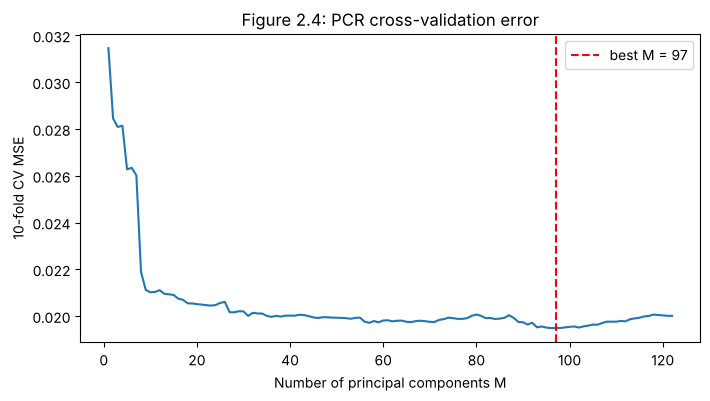

In [ ]:
pcr = Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("lr", LinearRegression())])
M_grid = list(range(1, X_train.shape[1] + 1))
pcr_cv = GridSearchCV(pcr, {"pca__n_components": M_grid}, cv=kf10,
                      scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
best_M = pcr_cv.best_params_["pca__n_components"]
mse_pcr = mean_squared_error(y_test, pcr_cv.predict(X_test))
print(f"Best M = {best_M}")
print(f"PCR test MSE = {mse_pcr:.5f}")
results["PCR"] = mse_pcr

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(M_grid, -pcr_cv.cv_results_["mean_test_score"])
ax.axvline(best_M, color="r", ls="--", label=f"best M = {best_M}")
ax.set_xlabel("Number of principal components M"); ax.set_ylabel("10-fold CV MSE")
ax.set_title("Figure 2.4: PCR cross-validation error"); ax.legend()
plt.show()

## 2(j) L1-penalized gradient boosting tree (XGBoost)

I fit an XGBoost regression tree ensemble with an L1 penalty `reg_alpha` ($\alpha$) on the leaf weights.
$\alpha$ is chosen by 10-fold cross-validation on the training set. The other hyper-parameters are fixed at
reasonable values (500 trees, learning rate 0.05, max depth 3, subsampling 0.8) to keep the search focused on $\alpha$.

In [ ]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, objective="reg:squarederror",
                   random_state=RANDOM_STATE, n_jobs=-1)
alpha_grid = {"reg_alpha": [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]}
xgb_cv = GridSearchCV(xgb, alpha_grid, cv=kf10, scoring="neg_mean_squared_error").fit(X_train, y_train)
best_a = xgb_cv.best_params_["reg_alpha"]
mse_xgb = mean_squared_error(y_test, xgb_cv.predict(X_test))
print(f"Best alpha = {best_a}")
print(f"XGBoost test MSE = {mse_xgb:.5f}")
results["XGBoost (L1)"] = mse_xgb

display(pd.DataFrame({"alpha": alpha_grid["reg_alpha"],
                      "CV MSE": -xgb_cv.cv_results_["mean_test_score"]}))

Best alpha = 2
XGBoost test MSE = 0.01572


,alpha,CV MSE
0,0.000,0.019492
1,0.001,0.019531
2,0.010,0.019580
3,0.050,0.019280
4,0.100,0.019231
5,0.500,0.019299
6,1.000,0.019078
7,2.000,0.019034
8,5.000,0.019329
9,10.000,0.020677


### Summary of test errors

In [ ]:
summary = pd.DataFrame.from_dict(results, orient="index", columns=["Test MSE"]).sort_values("Test MSE")
display(summary)

,Test MSE
XGBoost (L1),0.015720
Ridge,0.017527
LASSO,0.017688
LASSO (standardized),0.017721
Least squares,0.017966
PCR,0.018366


**Summary:** The L1-penalized boosting tree (XGBoost) has the lowest test MSE. It can capture non-linear effects
and interactions that the linear models miss. Among the linear models, Ridge and the two LASSO models are slightly
better than plain least squares: with 122 highly correlated features, shrinkage reduces variance. The LASSO
reaches about the same error while using only around 76–79 of the 122 features. PCR is slightly worse than least squares here.
CV picks a large number of components, so PCR is close to the full least-squares fit. The directions with the largest
variance in X are not necessarily the ones most related to the crime rate.

# References
1. UCI ML Repository, Acute Inflammations: https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations
2. UCI ML Repository, Communities and Crime: https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime
3. KDnuggets, *Simplifying Decision Tree Interpretability with Python & Scikit-learn*: https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
4. scikit-learn, Post pruning decision trees with cost complexity pruning: https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html
5. scikit-learn documentation: RidgeCV, LassoCV, PCA, GridSearchCV
6. XGBoost documentation, parameters (`reg_alpha`): https://xgboost.readthedocs.io/en/stable/parameter.html
7. James, Witten, Hastie, Tibshirani, *An Introduction to Statistical Learning*, Ch. 6 and 8